In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from matplotlib.gridspec import GridSpec
from matplotlib.lines import Line2D
from matplotlib.ticker import PercentFormatter

In [2]:
# ---
# Load data
# ---

reference = pd.read_excel(
    "data/combined_dataset.xlsx",
    sheet_name="EIA Data World",
    header=0,
)

df = pd.read_excel(
    "data/combined_dataset.xlsx",
    sheet_name="Dataset",
)

# Operating assets do not have a retirement year
df.loc[
    df["Status"] == "OP",
    "Retired Year",
] = np.nan


In [3]:
# ---
# Build cumulative operating capacity
# ---

df2 = df.copy()

# Clean year columns
df2["Start Year"] = pd.to_numeric(
    df2["Start Year"],
    errors="coerce",
)

df2["Retired Year"] = pd.to_numeric(
    df2["Retired Year"],
    errors="coerce",
)

df2 = df2.dropna(
    subset=["Start Year"],
)

df2["Start Year"] = df2["Start Year"].astype(int)
df2["Retired Year"] = df2["Retired Year"].astype("Int64")

# Additions: capacity entering operation
add_grouped = (
    df2.groupby(
        [
            "Start Year",
            "Technology",
        ]
    )["Capacity (MW)"]
    .sum()
    .reset_index()
    .rename(
        columns={
            "Start Year": "Year",
        }
    )
)

add_pivot = (
    add_grouped.pivot(
        index="Year",
        columns="Technology",
        values="Capacity (MW)",
    )
    .fillna(0)
)

# Retirements: remove capacity in the year after retirement
ret_grouped = (
    df2.dropna(
        subset=["Retired Year"],
    )
    .assign(
        Year=lambda data: data["Retired Year"] + 1,
    )
    .groupby(
        [
            "Year",
            "Technology",
        ]
    )["Capacity (MW)"]
    .sum()
    .reset_index()
)

ret_pivot = (
    ret_grouped.pivot(
        index="Year",
        columns="Technology",
        values="Capacity (MW)",
    )
    .fillna(0)
)

# Net annual change
all_years = sorted(
    set(add_pivot.index).union(
        ret_pivot.index,
    )
)

all_techs = sorted(
    set(add_pivot.columns).union(
        ret_pivot.columns,
    )
)

add_pivot = add_pivot.reindex(
    index=all_years,
    columns=all_techs,
    fill_value=0,
)

ret_pivot = ret_pivot.reindex(
    index=all_years,
    columns=all_techs,
    fill_value=0,
)

df_pivot = add_pivot - ret_pivot
df_pivot.index = df_pivot.index.astype(int)

# Aggregate technologies
df_pivot["Fossil"] = (
    df_pivot.get("Coal", 0)
    + df_pivot.get("Natural Gas", 0)
    + df_pivot.get("Oil", 0)
)

solar_techs = [
    col
    for col in df_pivot.columns
    if "solar" in col.lower() or "pv" in col.lower()
]

if solar_techs:
    df_pivot["Solar"] = df_pivot[
        solar_techs
    ].sum(axis=1)

wind_techs = [
    col
    for col in df_pivot.columns
    if "wind" in col.lower()
]

if wind_techs:
    df_pivot["Wind"] = df_pivot[
        wind_techs
    ].sum(axis=1)

relevant_columns = [
    "Fossil",
    "Hydropower",
    "Solar",
    "Wind",
    "Nuclear",
    "Bioenergy",
    "Geothermal",
]

df_pivot = df_pivot[
    [
        col
        for col in relevant_columns
        if col in df_pivot.columns
    ]
]

# Cumulative operating capacity
df_cumulative = df_pivot.cumsum()


In [4]:
# ---
# Prepare reference data
# ---

ref_grouped = (
    reference.groupby(
        [
            "Year",
            "Technology",
        ]
    )["Capacity (MW)"]
    .sum()
    .reset_index()
)

ref_pivot = (
    ref_grouped.pivot(
        index="Year",
        columns="Technology",
        values="Capacity (MW)",
    )
    .fillna(0)
)

ref_pivot.index = ref_pivot.index.astype(int)

# Preserve the original dataset-year selection
ref = ref_pivot.copy()
dfc = df_cumulative.iloc[85:-2].copy()

# Align both datasets to a common year index
years = sorted(
    set(ref.index).union(
        dfc.index,
    )
)

ref = ref.reindex(years)
dfc = dfc.reindex(years)


In [5]:
# ---
# Shared plotting configuration
# ---

MW_TO_GW = 1000

START_2000_TECHS = {
    "Solar",
    "Wind",
    "Bioenergy",
    "Geothermal",
}

tech_groups = {
    "Fossil fuels": [
        "Fossil",
    ],
    "Core transition technologies": [
        "Solar",
        "Wind",
        "Nuclear",
    ],
    "Other low-carbon technologies": [
        "Bioenergy",
        "Geothermal",
        "Hydropower",
    ],
}


# ---
# Style
# ---

FONT_BASE = 10.0
FONT_TICKS = 10.0
FONT_TITLE = 10.5
FONT_PANEL = 10.5
FONT_GROUP_HEADER = 11.0
FONT_AXIS_LABEL = 11.5
FONT_LEGEND = 10.0
FONT_ANNOTATION = 10.0

plt.rcParams.update(
    {
        "font.family": "Arial",
        "font.size": FONT_BASE,
        "axes.linewidth": 0.75,
        "axes.labelsize": FONT_AXIS_LABEL,
        "axes.titlesize": FONT_TITLE,
        "xtick.labelsize": FONT_TICKS,
        "ytick.labelsize": FONT_TICKS,
        "legend.fontsize": FONT_LEGEND,
        "xtick.direction": "out",
        "ytick.direction": "out",
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
        "savefig.dpi": 600,
    }
)


# ---
# Colours
# ---

REFERENCE_COLOUR = "#222222"
DATASET_COLOUR = "#3F708F"
DIFFERENCE_COLOUR = "#3F708F"
ZERO_LINE_COLOUR = "#222222"

TEXT_COLOUR = "#222222"
SECONDARY_TEXT_COLOUR = "#555555"
AXIS_COLOUR = "#444444"
GROUP_LINE_COLOUR = "#777777"
GRID_COLOUR = "#BFBFBF"
COLOR_BACKGROUND = "white"


# ---
# Shared helpers
# ---

# Return values for one technology.
def get_series_values(
    data,
    tech,
    years_array,
):
    n_years = len(years_array)

    if isinstance(data, pd.DataFrame):
        if tech in data.columns:
            values = data[tech].to_numpy(
                dtype=float,
            )
        else:
            values = np.zeros(
                n_years,
                dtype=float,
            )
    else:
        try:
            values = np.asarray(
                data[tech],
                dtype=float,
            )
        except (KeyError, TypeError):
            values = np.zeros(
                n_years,
                dtype=float,
            )

    # Ensure the vector length matches the year vector
    if len(values) != n_years:
        values_fixed = np.full(
            n_years,
            np.nan,
            dtype=float,
        )

        n_copy = min(
            len(values),
            n_years,
        )

        values_fixed[:n_copy] = values[:n_copy]
        values = values_fixed

    return values


# Return the last finite value in an array.
def get_last_finite_value(values):
    values = np.asarray(
        values,
        dtype=float,
    )

    finite_values = values[
        np.isfinite(values)
    ]

    if len(finite_values) == 0:
        return np.nan

    return finite_values[-1]


# Add a group heading and separator line.
def add_group_header(ax, title):
    ax.axis("off")

    ax.text(
        0.0,
        0.65,
        title,
        transform=ax.transAxes,
        ha="left",
        va="center",
        fontsize=FONT_GROUP_HEADER,
        fontweight="bold",
        color=TEXT_COLOUR,
    )

    ax.plot(
        [
            0.0,
            1.0,
        ],
        [
            0.15,
            0.15,
        ],
        transform=ax.transAxes,
        color=GROUP_LINE_COLOUR,
        linewidth=0.75,
        clip_on=False,
    )


# Return GridSpec positions for one technology group.
def get_panel_positions(
    row_index,
    n_panels,
):
    if n_panels == 4:
        return [
            (row_index, slice(0, 3)),
            (row_index, slice(3, 6)),
            (row_index, slice(6, 9)),
            (row_index, slice(9, 12)),
        ]

    if n_panels == 3:
        return [
            (row_index, slice(0, 4)),
            (row_index, slice(4, 8)),
            (row_index, slice(8, 12)),
        ]

    if n_panels == 2:
        return [
            (row_index, slice(0, 6)),
            (row_index, slice(6, 12)),
        ]

    if n_panels == 1:
        return [
            (row_index, slice(0, 12)),
        ]

    raise ValueError(
        "This layout expects 1 to 4 panels per group."
    )


# Apply common grid, spine, and tick styling.
def style_panel_axis(ax):
    ax.grid(
        axis="y",
        linestyle="-",
        linewidth=0.45,
        alpha=0.30,
        color=GRID_COLOUR,
        zorder=0,
    )

    ax.grid(
        axis="x",
        visible=False,
    )

    ax.set_axisbelow(True)

    for spine in [
        "top",
        "right",
    ]:
        ax.spines[spine].set_visible(False)

    for spine in [
        "left",
        "bottom",
    ]:
        ax.spines[spine].set_linewidth(0.75)
        ax.spines[spine].set_color(AXIS_COLOUR)

    ax.tick_params(
        axis="both",
        direction="out",
        length=3.2,
        width=0.75,
        pad=3,
        labelsize=FONT_TICKS,
        colors=TEXT_COLOUR,
    )


# Add the panel label and technology title.
def add_panel_heading(
    ax,
    tech,
    panel_label,
):
    panel_x = (
        -0.04
        if panel_label == "a"
        else -0.13
    )

    ax.text(
        panel_x,
        1.10,
        panel_label,
        transform=ax.transAxes,
        ha="left",
        va="top",
        fontsize=FONT_PANEL,
        fontweight="bold",
        color=TEXT_COLOUR,
    )

    ax.set_title(
        tech,
        fontsize=FONT_TITLE,
        fontweight="bold",
        pad=6,
        color=TEXT_COLOUR,
    )


# Set year limits and 20-year tick intervals.
def set_year_axis(
    ax,
    years_array,
):
    ax.set_xlim(
        np.nanmin(years_array),
        np.nanmax(years_array),
    )

    x_tick_start = int(
        np.floor(
            np.nanmin(years_array) / 20
        )
        * 20
    )

    x_tick_end = int(
        np.ceil(
            np.nanmax(years_array) / 20
        )
        * 20
    )

    ax.set_xticks(
        np.arange(
            x_tick_start,
            x_tick_end + 1,
            20,
        )
    )


# Create the shared grouped figure layout.
def create_grouped_figure():
    group_names = list(
        tech_groups.keys()
    )

    height_ratios = [
        value
        for _ in group_names
        for value in (
            0.18,
            1.0,
        )
    ]

    fig = plt.figure(
        figsize=(11.8, 9.3),
        facecolor=COLOR_BACKGROUND,
    )

    gs = GridSpec(
        nrows=len(group_names) * 2,
        ncols=12,
        figure=fig,
        height_ratios=height_ratios,
        hspace=0.38,
        wspace=0.85,
    )

    return fig, gs, group_names


# Populate the shared grouped layout using a panel function.
def populate_grouped_panels(
    fig,
    gs,
    group_names,
    plot_function,
):
    panel_counter = 0

    for group_index, group_name in enumerate(
        group_names
    ):
        header_row = group_index * 2
        panel_row = header_row + 1

        ax_header = fig.add_subplot(
            gs[header_row, :]
        )

        add_group_header(
            ax_header,
            group_name,
        )

        tech_list = tech_groups[
            group_name
        ]

        positions = get_panel_positions(
            panel_row,
            len(tech_list),
        )

        for tech, (
            row_index,
            col_slice,
        ) in zip(
            tech_list,
            positions,
        ):
            ax = fig.add_subplot(
                gs[
                    row_index,
                    col_slice,
                ]
            )

            ax.set_facecolor(
                COLOR_BACKGROUND,
            )

            plot_function(
                ax=ax,
                tech=tech,
                panel_label=chr(
                    97 + panel_counter
                ),
            )

            panel_counter += 1


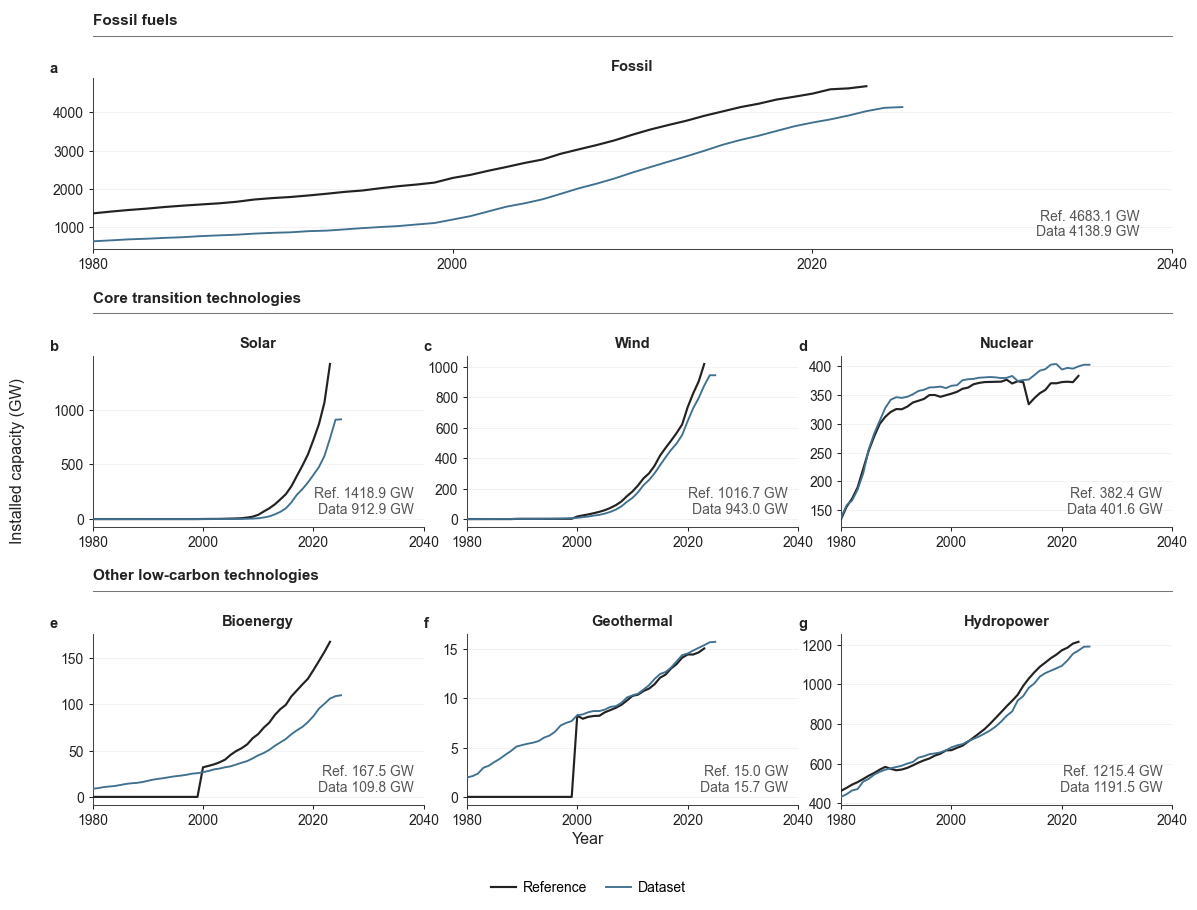

In [6]:
# ---
# Cumulative installed capacity comparison
# ---

years_array = np.asarray(
    years,
    dtype=float,
)


# Plot reference and dataset capacity for one technology.
def plot_capacity_comparison_panel(
    ax,
    tech,
    panel_label,
):
    reference_values = (
        get_series_values(
            ref,
            tech,
            years_array,
        )
        / MW_TO_GW
    )

    dataset_values = (
        get_series_values(
            dfc,
            tech,
            years_array,
        )
        / MW_TO_GW
    )

    # Capacity trajectories
    ax.plot(
        years_array,
        reference_values,
        color=REFERENCE_COLOUR,
        linewidth=1.55,
        label="Reference",
        zorder=4,
    )

    ax.plot(
        years_array,
        dataset_values,
        color=DATASET_COLOUR,
        linewidth=1.35,
        label="Dataset",
        zorder=5,
    )

    # Final-value annotation
    ref_final = get_last_finite_value(
        reference_values
    )

    data_final = get_last_finite_value(
        dataset_values
    )

    ax.text(
        0.97,
        0.06,
        (
            f"Ref. {ref_final:.1f} GW\n"
            f"Data {data_final:.1f} GW"
        ),
        transform=ax.transAxes,
        ha="right",
        va="bottom",
        fontsize=FONT_ANNOTATION,
        fontweight="normal",
        color=SECONDARY_TEXT_COLOUR,
        linespacing=1.15,
        zorder=6,
    )

    add_panel_heading(
        ax,
        tech,
        panel_label,
    )

    set_year_axis(
        ax,
        years_array,
    )

    style_panel_axis(
        ax,
    )


# ---
# Build figure
# ---

fig, gs, group_names = create_grouped_figure()

populate_grouped_panels(
    fig,
    gs,
    group_names,
    plot_capacity_comparison_panel,
)

fig.supylabel(
    "Installed capacity (GW)",
    fontsize=FONT_AXIS_LABEL,
    fontweight="normal",
    x=0.010,
    color=TEXT_COLOUR,
)

fig.supxlabel(
    "Year",
    fontsize=FONT_AXIS_LABEL,
    fontweight="normal",
    y=0.085,
    color=TEXT_COLOUR,
)

legend_handles = [
    Line2D(
        [0],
        [0],
        color=REFERENCE_COLOUR,
        linewidth=1.55,
        label="Reference",
    ),
    Line2D(
        [0],
        [0],
        color=DATASET_COLOUR,
        linewidth=1.35,
        label="Dataset",
    ),
]

fig.legend(
    handles=legend_handles,
    frameon=False,
    loc="lower center",
    bbox_to_anchor=(
        0.5,
        0.020,
    ),
    ncol=2,
    fontsize=FONT_LEGEND,
    columnspacing=1.35,
    handlelength=1.8,
    handletextpad=0.50,
)

fig.subplots_adjust(
    left=0.080,
    right=0.995,
    bottom=0.130,
    top=0.985,
)


# ---
# Save
# ---
plt.savefig(

    "figures/si/figure-2.png",
    dpi=600,
    bbox_inches="tight",
    transparent=True,
)
plt.savefig(
    "figures/si/figure-2.pdf",
    dpi=600,
    bbox_inches="tight",
    transparent=True,)

plt.show()


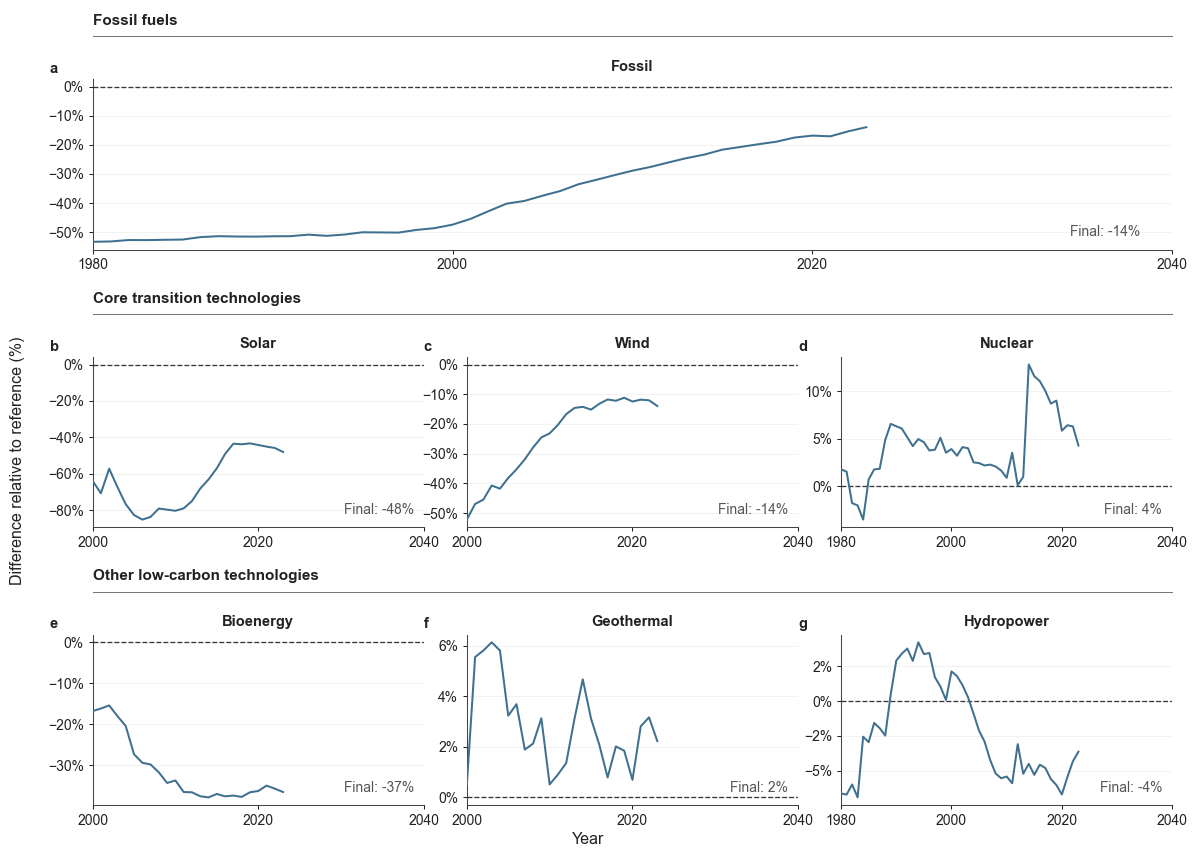

In [7]:
# ---
# Cumulative capacity difference
# ---

# Difference (%) = (Dataset - Reference) / Reference * 100


# Plot percentage difference relative to the reference.
def plot_difference_panel(
    ax,
    tech,
    panel_label,
):
    reference_values = get_series_values(
        ref,
        tech,
        years_array,
    )

    dataset_values = get_series_values(
        dfc,
        tech,
        years_array,
    )

    # Show selected technologies only from 2000 onwards
    if tech in START_2000_TECHS:
        mask = years_array >= 2000
    else:
        mask = np.isfinite(
            years_array
        )

    x = years_array[mask]
    reference_y = reference_values[mask]
    dataset_y = dataset_values[mask]

    # Percentage difference, excluding zero reference values
    pct_diff = np.full_like(
        reference_y,
        np.nan,
        dtype=float,
    )

    valid = (
        np.isfinite(reference_y)
        & np.isfinite(dataset_y)
        & (reference_y != 0)
    )

    pct_diff[valid] = (
        (
            dataset_y[valid]
            - reference_y[valid]
        )
        / reference_y[valid]
        * 100
    )

    # Difference trajectory
    ax.plot(
        x,
        pct_diff,
        linestyle="-",
        color=DIFFERENCE_COLOUR,
        linewidth=1.45,
        zorder=4,
    )

    # Zero reference line
    ax.axhline(
        0,
        color=ZERO_LINE_COLOUR,
        linestyle="--",
        linewidth=0.95,
        alpha=0.90,
        zorder=3,
    )

    # Final-value annotation
    final_diff = get_last_finite_value(
        pct_diff
    )

    ax.text(
        0.97,
        0.06,
        f"Final: {final_diff:.0f}%",
        transform=ax.transAxes,
        ha="right",
        va="bottom",
        fontsize=FONT_ANNOTATION,
        fontweight="normal",
        color=SECONDARY_TEXT_COLOUR,
        zorder=6,
    )

    add_panel_heading(
        ax,
        tech,
        panel_label,
    )

    set_year_axis(
        ax,
        x,
    )

    ax.yaxis.set_major_formatter(
        PercentFormatter(
            xmax=100,
            decimals=0,
        )
    )

    style_panel_axis(
        ax,
    )


# ---
# Build figure
# ---

fig, gs, group_names = create_grouped_figure()

populate_grouped_panels(
    fig,
    gs,
    group_names,
    plot_difference_panel,
)

fig.supylabel(
    "Difference relative to reference (%)",
    fontsize=FONT_AXIS_LABEL,
    fontweight="normal",
    x=0.010,
    color=TEXT_COLOUR,
)

fig.supxlabel(
    "Year",
    fontsize=FONT_AXIS_LABEL,
    fontweight="normal",
    y=0.085,
    color=TEXT_COLOUR,
)

fig.subplots_adjust(
    left=0.080,
    right=0.995,
    bottom=0.130,
    top=0.985,
)


# ---
# Save
# ---
plt.savefig(
    "figures/si/figure-3.png",
    dpi=600,
    bbox_inches="tight",
    transparent=True,
)
plt.savefig(
    "figures/si/figure-3.pdf",
    dpi=600,
    bbox_inches="tight",
    transparent=True
)

plt.show()
